#第七章：Numpy库

## NumPy 教学展示 Notebook

本 notebook 根据用户提供的课件内容重组而成，适合课堂演示与边讲边练。主题聚焦于：

- 数据的维度
- `ndarray` 的创建与属性
- 数组索引、切片与变换
- 数组运算与统计函数
- 图像的数组表示与简单变换

> 建议课堂节奏：讲解 20～30 分钟，演示 15 分钟，练习 10 分钟。


## 0. 课堂目标

完成本节后，你应该能够：

1. 说清楚一维、二维、多维数据的区别  
2. 使用 NumPy 创建常见数组  
3. 读懂 `ndarray` 的常用属性：`ndim`、`shape`、`size`、`dtype`  
4. 对数组进行索引、切片、变形和基础运算  
5. 使用统计函数对数组做简单分析  
6. 理解“图像本质上也是数组”


## 配套课件展示

下面先按课件顺序看几页原始幻灯片，再用后续代码单元做演示。这样课堂节奏会更自然：**先看图，再运行代码，再总结规律**。

### 课件页 1：从一个数据到一组数据

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-01.png" alt="课件页 1：从一个数据到一组数据" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

先展示课件中的直观例子，再进入 notebook 的维度讲解。

### 课件页 2：一组数据可以怎样组织

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-02.png" alt="课件页 2：一组数据可以怎样组织" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

这一页适合引出“一维展开”和“二维展开”的区别。

### 课件页 3：一维数据

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-03.png" alt="课件页 3：一维数据" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

讲这一页时，可让学生先观察：这些数据之间是并列关系还是层次关系？

### 课件页 4：二维数据

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-04.png" alt="课件页 4：二维数据" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

可结合表格、成绩单、座位表等例子说明二维数据。

### 课件页 5：多维数据

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-05.png" alt="课件页 5：多维数据" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

这里可以顺势说明：增加一个时间维度后，二维表就可以扩展为多维数据。

### 课件页 6：高维数据与 Python 表示

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-06.png" alt="课件页 6：高维数据与 Python 表示" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

这页适合和列表、嵌套列表、字典的表示方式对应起来。

## 1. 数据的维度

课件强调：**维度是“一组数据的组织形式”**。  
理解 NumPy 之前，先理解数据是如何被组织的。

- **一维数据**：线性组织，例如成绩列表、温度序列
- **二维数据**：表格组织，例如学生成绩表
- **多维数据**：在二维基础上增加新的维度，例如“年份 × 学生 × 科目”
- **高维数据**：常见于字典/JSON，强调键值关系而非整齐表格


In [3]:
# 一维数据：一个列表
one_d = [88, 92, 79, 93, 85]
print("一维数据:", one_d)

# 二维数据：嵌套列表
two_d = [
    ["张三", 88, 92],
    ["李四", 79, 85],
    ["王五", 93, 90]
]
print("\n二维数据:")
for row in two_d:
    print(row)

# 三维数据：例如 年份 × 班级 × 成绩
three_d = [
    [[80, 85], [78, 90]],   # 第1年
    [[82, 88], [81, 91]]    # 第2年
]
print("\n三维数据:", three_d)


一维数据: [88, 92, 79, 93, 85]

二维数据:
['张三', 88, 92]
['李四', 79, 85]
['王五', 93, 90]

三维数据: [[[80, 85], [78, 90]], [[82, 88], [81, 91]]]


### 思考

为什么只用 Python 列表还不够？  
因为当数据量变大、需要统一类型、需要大量数值运算时，列表效率和表达方式都不够理想。  
这就是 `NumPy.ndarray` 的价值所在。


## 配套课件展示

下面先按课件顺序看几页原始幻灯片，再用后续代码单元做演示。这样课堂节奏会更自然：**先看图，再运行代码，再总结规律**。

### 课件页 7：为什么学习 NumPy

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-07.png" alt="课件页 7：为什么学习 NumPy" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

讲解重点：NumPy 是高效数值计算的基础库，核心对象是 `ndarray`。

### 课件页 8：列表做数值计算需要循环

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-08.png" alt="课件页 8：列表做数值计算需要循环" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

先让学生看到传统写法，再过渡到向量化计算。

### 课件页 9：数组可以直接整体运算

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-09.png" alt="课件页 9：数组可以直接整体运算" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

这一页非常适合作为“向量化”思想的第一印象。

### 课件页 10：`ndarray` 的结构与属性

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-10.png" alt="课件页 10：ndarray 的结构与属性" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

展示完课件页，再让学生在下面的代码单元里实际查看 `.shape`、`.dtype` 等属性。

## 2. NumPy 入门：为什么用 ndarray？

课件指出，数组对象可以：

- 去掉大量元素级循环
- 让一维向量“更像一个整体”
- 提升科学计算效率

下面先导入 NumPy。


In [14]:
import numpy as np

## 配套课件展示

下面先按课件顺序看几页原始幻灯片，再用后续代码单元做演示。这样课堂节奏会更自然：**先看图，再运行代码，再总结规律**。

### 课件页 11：常见创建方式

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-11.png" alt="课件页 11：常见创建方式" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

建议按 `array` → `arange` → `zeros/ones` → `linspace` 的顺序讲。

### 课件页 12：`linspace` 与 `concatenate`

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-12.png" alt="课件页 12：linspace 与 concatenate" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

这里可以提醒学生：NumPy 默认很喜欢返回浮点数数组。

## 3. 创建 ndarray

### 3.1 从列表或元组创建


In [26]:
a = np.array([0, 1, 2, 3])
print(a.shape)
b = np.array((4, 5, 6, 7))
c = np.array([[1, 2], [9, 8], (0.1, 0.2)])

print("a =", a)
print("b =", b)
print("c =\n", c)


(4,)
a = [0 1 2 3]
b = [4 5 6 7]
c =
 [[1.  2. ]
 [9.  8. ]
 [0.1 0.2]]


### 3.2 指定元素类型 `dtype`


In [17]:
x1 = np.array([1, 2, 3])
print(x1)
x2 = np.array([1, 2, 3], dtype=np.float32)
print(x2)

print("默认 dtype:", x1.dtype)
print("指定 dtype:", x2.dtype)


[1 2 3]
[1. 2. 3.]
默认 dtype: int64
指定 dtype: float32


### 3.3 使用 NumPy 常用函数创建

课件重点包括：

- `np.arange()`
- `np.ones()`
- `np.zeros()`
- `np.full()`
- `np.eye()`
- `np.linspace()`
- `np.concatenate()`


In [21]:
arr1 = np.arange(10)
arr2 = np.ones((2, 3))
arr3 = np.zeros((2, 3), dtype=np.int32)
arr4 = np.full((2, 3), 7)
arr5 = np.eye(4)
arr6 = np.linspace(1, 10, 4)

print("np.arange(10) =", arr1)
print("\nnp.ones((2,3)) =\n", arr2)
print("\nnp.zeros((2,3), dtype=np.int32) =\n", arr3)
print("\nnp.full((2,3), 7) =\n", arr4)
print("\nnp.eye(4) =\n", arr5)
print("\nnp.linspace(1, 10, 4) =", arr6)


np.arange(10) = [0 1 2 3 4 5 6 7 8 9]

np.ones((2,3)) =
 [[1. 1. 1.]
 [1. 1. 1.]]

np.zeros((2,3), dtype=np.int32) =
 [[0 0 0]
 [0 0 0]]

np.full((2,3), 7) =
 [[7 7 7]
 [7 7 7]]

np.eye(4) =
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

np.linspace(1, 10, 4) = [ 1.  4.  7. 10.]


In [8]:
a = np.linspace(1, 10, 4)
b = np.linspace(1, 10, 4, endpoint=False)
c = np.concatenate((a, b))

print("a =", a)
print("b =", b)
print("c =", c)


a = [ 1.  4.  7. 10.]
b = [1.   3.25 5.5  7.75]
c = [ 1.    4.    7.   10.    1.    3.25  5.5   7.75]


### 课堂提示

- `arange` 更像 Python 的 `range`
- `ones / zeros / full / eye` 经常用于构造测试数据
- `linspace` 在数学建模和绘图时非常常见


## 4. ndarray 的常用属性

课件中重点属性有：

- `ndim`：维度数
- `shape`：各维长度
- `size`：元素总数
- `dtype`：元素类型
- `itemsize`：每个元素所占字节数


In [9]:
a = np.array([[0, 1, 2, 3, 4],
              [9, 8, 7, 6, 5]])

print("a =\n", a)
print("a.ndim =", a.ndim)
print("a.shape =", a.shape)
print("a.size =", a.size)
print("a.dtype =", a.dtype)
print("a.itemsize =", a.itemsize)


a =
 [[0 1 2 3 4]
 [9 8 7 6 5]]
a.ndim = 2
a.shape = (2, 5)
a.size = 10
a.dtype = int64
a.itemsize = 8


### 小结

如果 `shape = (2, 5)`，可理解为：

- 第 1 个维度有 2 个元素
- 第 2 个维度有 5 个元素


## 5. 为什么 ndarray 比列表更适合数值计算？

课件用了一个典型思想：  
把数组当作一个整体来计算，而不是用 `for` 循环一个个处理。


In [10]:
# 用列表实现：A^2 + B^3
A_list = [1, 2, 3, 4]
B_list = [5, 6, 7, 8]

result_list = []
for i in range(len(A_list)):
    result_list.append(A_list[i] ** 2 + B_list[i] ** 3)

print("列表方式结果:", result_list)

# 用 NumPy 实现
A = np.array(A_list)
B = np.array(B_list)
result_np = A ** 2 + B ** 3

print("NumPy 方式结果:", result_np)


列表方式结果: [126, 220, 352, 528]
NumPy 方式结果: [126 220 352 528]


## 6. 索引与切片

NumPy 的索引与切片和 Python 类似，但支持多维一起操作。


In [22]:
a = np.arange(24).reshape((2, 3, 4))
b = np.arange(24)
print(b)

print("a =\n", a)
print("\na.shape =", a.shape)


[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
a =
 [[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]

a.shape = (2, 3, 4)


In [23]:
print("取一个元素 a[1, 2, 3] =", a[1, 2, 3])
print("取一个元素 a[1, 2, 3] =", a[1][2][3])
print("\n取整个第一维中的第0个块 a[0] =\n", a[0])
print("\n切片 a[:, 1:3, :] =\n", a[:, 1:3, :])
print("\n步长切片 a[:, :, ::2] =\n", a[:, :, ::2])


取一个元素 a[1, 2, 3] = 23
取一个元素 a[1, 2, 3] = 23

取整个第一维中的第0个块 a[0] =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

切片 a[:, 1:3, :] =
 [[[ 4  5  6  7]
  [ 8  9 10 11]]

 [[16 17 18 19]
  [20 21 22 23]]]

步长切片 a[:, :, ::2] =
 [[[ 8 10]]]


### 讲解建议

可把 `a.shape = (2, 3, 4)` 读成：

- 第 1 维：2 个大块
- 第 2 维：每块 3 行
- 第 3 维：每行 4 个元素

这样学生更容易理解 `a[:, 1:3, :]` 的含义。


## 配套课件展示

下面先按课件顺序看几页原始幻灯片，再用后续代码单元做演示。这样课堂节奏会更自然：**先看图，再运行代码，再总结规律**。

### 课件页 13：`reshape` / `resize` / `flatten`

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-13.png" alt="课件页 13：reshape / resize / flatten" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

这一页的重点不是函数名，而是“是否改变原数组”。

## 7. 数组变换

课件重点介绍：

- `reshape()`：返回新数组，不改原数组
- `resize()`：直接改原数组
- `swapaxes()`：交换两个轴
- `flatten()`：拉平成一维


In [13]:
a = np.ones((2, 3, 4), dtype=np.int32)
print("原数组 a.shape =", a.shape)

b = a.reshape((3, 8))
print("reshape 后 b.shape =", b.shape)
print("原数组 a.shape 仍然是 =", a.shape)


原数组 a.shape = (2, 3, 4)
reshape 后 b.shape = (3, 8)
原数组 a.shape 仍然是 = (2, 3, 4)


In [11]:
a = np.ones((2, 3, 4), dtype=np.int32)
print("resize 前 a.shape =", a.shape)

a.resize((3, 8))
print("resize 后 a.shape =", a.shape)
print(a)


resize 前 a.shape = (2, 3, 4)
resize 后 a.shape = (3, 8)
[[1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]]


In [25]:
a = np.arange(24).reshape((2, 3, 4))
print("原 shape:", a.shape)
print(a)

b = a.swapaxes(0, 2)
print("交换轴后 shape:", b.shape)
print(b)

c = a.flatten()
print("flatten 后 shape:", c.shape)
print(c)


原 shape: (2, 3, 4)
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]
交换轴后 shape: (4, 3, 2)
[[[ 0 12]
  [ 4 16]
  [ 8 20]]

 [[ 1 13]
  [ 5 17]
  [ 9 21]]

 [[ 2 14]
  [ 6 18]
  [10 22]]

 [[ 3 15]
  [ 7 19]
  [11 23]]]
flatten 后 shape: (24,)
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]


### 易错点

- `reshape()`：通常**不改原数组**
- `resize()`：**直接改原数组**


## 配套课件展示

下面先按课件顺序看几页原始幻灯片，再用后续代码单元做演示。这样课堂节奏会更自然：**先看图，再运行代码，再总结规律**。

### 课件页 14：数组与标量运算

<div style="margin: 12px 0;">
  <img src="./resources/numpy-slide-14.png" alt="课件页 14：数组与标量运算" width="95%" style="border:1px solid #ddd; border-radius:6px;" />
</div>

这页展示了数组运算会作用到每个元素，是后面广播和统计计算的基础。

## 8. 数组与标量、数组之间的运算

课件强调：**数组与标量的运算会作用到每个元素上。**


In [16]:
a = np.arange(12).reshape((3, 4))
print("a =\n", a)

print("\na + 10 =\n", a + 10)
print("\na * 2 =\n", a * 2)
print("\na / a.mean() =\n", a / a.mean())


a =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

a + 10 =
 [[10 11 12 13]
 [14 15 16 17]
 [18 19 20 21]]

a * 2 =
 [[ 0  2  4  6]
 [ 8 10 12 14]
 [16 18 20 22]]

a / a.mean() =
 [[0.         0.18181818 0.36363636 0.54545455]
 [0.72727273 0.90909091 1.09090909 1.27272727]
 [1.45454545 1.63636364 1.81818182 2.        ]]


In [17]:
x = np.array([1, 2, 3])
y = np.array([10, 20, 30])

print("x + y =", x + y)
print("x * y =", x * y)
print("x ** 2 =", x ** 2)


x + y = [11 22 33]
x * y = [10 40 90]
x ** 2 = [1 4 9]


## 9. 常用一元函数

课件给出的例子包括：

- `np.abs`
- `np.sqrt`
- `np.square`
- `np.log / np.log10 / np.log2`
- `np.ceil / np.floor`


In [18]:
x = np.array([-4, -1, 0, 1, 4, 9], dtype=np.float64)

print("x =", x)
print("abs(x) =", np.abs(x))
print("square(x) =", np.square(x))
print("sqrt(abs(x)) =", np.sqrt(np.abs(x)))
print("ceil(x / 2) =", np.ceil(x / 2))
print("floor(x / 2) =", np.floor(x / 2))


x = [-4. -1.  0.  1.  4.  9.]
abs(x) = [4. 1. 0. 1. 4. 9.]
square(x) = [16.  1.  0.  1. 16. 81.]
sqrt(abs(x)) = [2. 1. 0. 1. 2. 3.]
ceil(x / 2) = [-2. -0.  0.  1.  2.  5.]
floor(x / 2) = [-2. -1.  0.  0.  2.  4.]


## 10. 统计函数

课件中重点讲了这些统计函数：

- `np.sum`
- `np.mean`
- `np.average`
- `np.std`
- `np.var`

其中 `axis` 是非常重要的参数。


In [19]:
a = np.arange(15).reshape(3, 5)
print("a =\n", a)

print("\nnp.sum(a) =", np.sum(a))
print("np.mean(a, axis=0) =", np.mean(a, axis=0))  # 按列
print("np.mean(a, axis=1) =", np.mean(a, axis=1))  # 按行
print("np.std(a) =", np.std(a))
print("np.var(a) =", np.var(a))


a =
 [[ 0  1  2  3  4]
 [ 5  6  7  8  9]
 [10 11 12 13 14]]

np.sum(a) = 105
np.mean(a, axis=0) = [5. 6. 7. 8. 9.]
np.mean(a, axis=1) = [ 2.  7. 12.]
np.std(a) = 4.320493798938574
np.var(a) = 18.666666666666668


In [20]:
scores = np.array([[80, 90, 70],
                   [85, 88, 92],
                   [78, 95, 89]])

weights = np.array([0.2, 0.3, 0.5])  # 三门课权重
weighted_avg = np.average(scores, axis=1, weights=weights)

print("scores =\n", scores)
print("每位同学的加权平均分 =", weighted_avg)


scores =
 [[80 90 70]
 [85 88 92]
 [78 95 89]]
每位同学的加权平均分 = [78.  89.4 88.6]


### 讲解建议：如何理解 `axis`

对二维数组而言：

- `axis=0`：沿着“行方向”压缩，结果保留列  
- `axis=1`：沿着“列方向”压缩，结果保留行


## 11. 随机数与数据生成

课件提到了 `np.random` 子库，它适合直接生成数组形式的随机数据。


In [21]:
np.random.seed(42)  # 为了教学演示可复现

print("rand(2,3) =\n", np.random.rand(2, 3))
print("\nrandn(2,3) =\n", np.random.randn(2, 3))
print("\nrandint(0, 10, size=(2,4)) =\n", np.random.randint(0, 10, size=(2, 4)))


rand(2,3) =
 [[0.37454012 0.95071431 0.73199394]
 [0.59865848 0.15601864 0.15599452]]

randn(2,3) =
 [[ 1.57921282  0.76743473 -0.46947439]
 [ 0.54256004 -0.46341769 -0.46572975]]

randint(0, 10, size=(2,4)) =
 [[9 5 8 0]
 [9 2 6 3]]


## 12. 多维数据的保存与读取

课件中介绍了：

- `np.save()` / `np.savez()`
- `np.load()`

下面做一个最小示例。


In [22]:
a = np.arange(20).reshape(2, 5, 2)
np.save("demo_array.npy", a)
b = np.load("demo_array.npy")

print("原数组 a.shape =", a.shape)
print("读取后 b.shape =", b.shape)
print("a 与 b 内容是否一致：", np.array_equal(a, b))


原数组 a.shape = (2, 5, 2)
读取后 b.shape = (2, 5, 2)
a 与 b 内容是否一致： True


## 13. 图像为什么可以看作数组？

课件指出：  
**图像本质上是由像素组成的矩阵，而彩色图像的每个像素通常有 RGB 三个值。**

为了保证本 notebook 不依赖外部图片文件，这里我们自己“造”一张彩色渐变图。


In [23]:
# 生成一张 120 x 180 的 RGB 图像数组
height, width = 120, 180

img = np.zeros((height, width, 3), dtype=np.uint8)

# 红色通道：从左到右渐变
img[:, :, 0] = np.linspace(0, 255, width, dtype=np.uint8)

# 绿色通道：从上到下渐变
img[:, :, 1] = np.linspace(0, 255, height, dtype=np.uint8).reshape(-1, 1)

# 蓝色通道：固定值
img[:, :, 2] = 120

print("图像数组 shape:", img.shape)
print("图像数组 dtype:", img.dtype)


图像数组 shape: (120, 180, 3)
图像数组 dtype: uint8


D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26500 (\N{CJK UNIFIED IDEOGRAPH-6784}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 36896 (\N{CJK UNIFIED IDEOGRAPH-9020}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20687 (\N{CJK UNIFIED IDEOGRAPH-50CF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


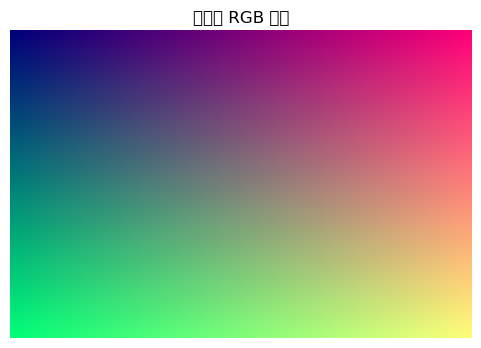

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.imshow(img)
plt.title("构造的 RGB 图像")
plt.axis("off")
plt.show()


## 14. 图像数组变换示例：颜色反转

课件中的经典思路是：

```python
b = [255, 255, 255] - a
```

这相当于把每个像素做“反色”处理。


D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21453 (\N{CJK UNIFIED IDEOGRAPH-53CD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 33394 (\N{CJK UNIFIED IDEOGRAPH-8272}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21518 (\N{CJK UNIFIED IDEOGRAPH-540E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


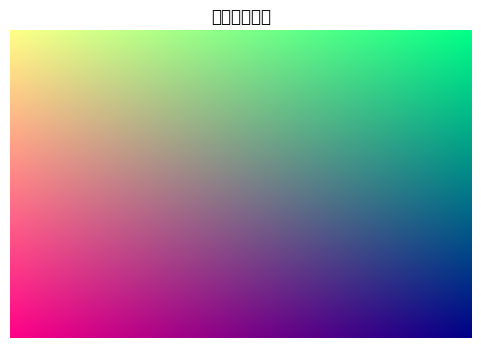

In [25]:
img_inverted = 255 - img

plt.figure(figsize=(6, 4))
plt.imshow(img_inverted)
plt.title("反色后的图像")
plt.axis("off")
plt.show()


## 15. 课堂练习

请先自己写，再展开参考答案。

### 练习 1
创建一个 `3 x 4` 的全 0 整数数组。

### 练习 2
创建数组 `0~11`，并把它变成 `3 x 4` 的二维数组。

### 练习 3
对二维数组按行求平均值。

### 练习 4
将一张图像数组做“上下翻转”。


练习1：
 [[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]

练习2：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

练习3： [1.5 5.5 9.5]


D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 19979 (\N{CJK UNIFIED IDEOGRAPH-4E0B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 32763 (\N{CJK UNIFIED IDEOGRAPH-7FFB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 36716 (\N{CJK UNIFIED IDEOGRAPH-8F6C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


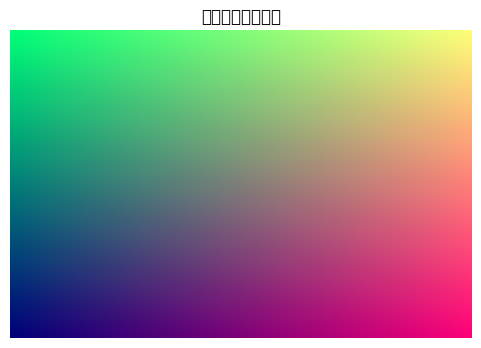

In [26]:
# 参考答案

# 练习1
ex1 = np.zeros((3, 4), dtype=np.int32)

# 练习2
ex2 = np.arange(12).reshape((3, 4))

# 练习3
ex3 = np.mean(ex2, axis=1)

# 练习4
flipped = img[::-1, :, :]

print("练习1：\n", ex1)
print("\n练习2：\n", ex2)
print("\n练习3：", ex3)

plt.figure(figsize=(6, 4))
plt.imshow(flipped)
plt.title("上下翻转后的图像")
plt.axis("off")
plt.show()


## 16. 本节总结

今天的核心不是记住所有函数，而是掌握三个观念：

1. **数据有维度，维度体现数据组织方式**
2. **`ndarray` 让数组成为“可以整体运算的数据对象”**
3. **图像、表格、随机数据，本质上都能转化为数组处理**

---
### 可继续扩展的方向
- 广播机制（broadcasting）
- 布尔索引
- 矩阵运算与线性代数
- 与 Pandas / Matplotlib 联动
